# Is this Elo model actually calibrated?

A probability is only worth something if it means what it says. This notebook takes the free 2,000-row sample and checks, from scratch, whether the model's stated confidence matches what actually happened.

Nothing is taken on trust — every number is recomputed from the CSV.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

m = pd.read_csv("../data/tt_ratings_sample_2000.csv", parse_dates=["date"])
print(f"{len(m):,} matches | {m.date.min().date()} to {m.date.max().date()} | {m.league.nunique()} competitions")
m.head()


2,000 matches | 2026-06-25 to 2026-08-18 | 25 competitions


,match_id,date,league,player_a,player_b,elo_a_pre,elo_b_pre,sol_a_pre,sol_b_pre,p_model,winner,sets_a,sets_b
0,8a6f481b9819,2026-06-25,Setka Cup,9de380f87e24,2aefe6feecb6,1494.0,1508.8,0.500,0.5,0.4636,A,3,1
1,59bb6a3fbc2f,2026-06-25,Czech Liga Pro,0f5e6305df44,57475d931cd1,1500.3,1512.5,0.500,0.5,0.4701,A,3,1
2,ef7c384c5a2b,2026-06-25,Setka Cup,49b72da6d5d0,122d76d9d81d,1510.9,1511.9,0.500,0.5,0.4976,B,0,3
3,09b0d01912db,2026-06-25,TT Elite Series,b6c45f10abe1,e83ef00a6810,1516.6,1506.2,0.667,0.6,0.5278,B,2,3
4,6b64017236fe,2026-06-25,Setka Cup,fa8e5c3975da,57a9ec775216,1507.7,1510.8,0.500,0.5,0.4924,A,3,1


## 1. The columns that matter

`elo_a_pre` and `elo_b_pre` are the two players' ratings **before** the match. `p_model` is the model's probability that player A wins, derived from those ratings alone. `winner` is what actually happened.

The entire value of the dataset rests on one property: nothing in a `_pre` column may depend on the result.


In [2]:
m[["date", "league", "elo_a_pre", "elo_b_pre", "p_model", "winner", "sets_a", "sets_b"]].head(8)


,date,league,elo_a_pre,elo_b_pre,p_model,winner,sets_a,sets_b
0,2026-06-25,Setka Cup,1494.0,1508.8,0.4636,A,3,1
1,2026-06-25,Czech Liga Pro,1500.3,1512.5,0.4701,A,3,1
2,2026-06-25,Setka Cup,1510.9,1511.9,0.4976,B,0,3
3,2026-06-25,TT Elite Series,1516.6,1506.2,0.5278,B,2,3
4,2026-06-25,Setka Cup,1507.7,1510.8,0.4924,A,3,1
5,2026-06-25,TT Elite Series,1485.0,1512.5,0.4329,B,2,3
6,2026-06-25,Czech Liga Pro,1505.7,1491.2,0.5357,B,1,3
7,2026-06-25,Setka Cup,1495.2,1495.2,0.5000,A,3,2


## 2. Sanity check — is there a side bias?

If player A won far more or less than half the time, the "A" slot would carry information by itself and every probability would be suspect.


In [3]:
y = (m.winner == "A").astype(int)
print(f"player A wins {y.mean():.1%} of matches")


player A wins 49.3% of matches


## 3. Scoring

The Brier score is the mean squared error of a probabilistic forecast — lower is better. Always predicting 50/50 scores 0.2500, so anything at or above that means the model adds nothing.


In [4]:
brier_model = ((m.p_model - y) ** 2).mean()
brier_naive = ((0.5       - y) ** 2).mean()

print(f"model         {brier_model:.4f}")
print(f"always 50/50  {brier_naive:.4f}")
print(f"improvement   {brier_naive - brier_model:+.4f}")


model         0.2422
always 50/50  0.2500
improvement   +0.0078


## 4. The real test: calibration

Brier rewards being confident *and* right, so a poorly calibrated model can still score acceptably. Calibration asks the sharper question: **when the model says 70%, does it win 70% of the time?**

We bucket predictions by stated confidence and compare against reality. Crucially, we also compute a **Wilson 95% confidence interval** for each bucket — with only a few dozen matches in the high bands, the observed rate carries real uncertainty, and pretending otherwise would be the exact sin this dataset is meant to avoid.


In [5]:
def wilson(k, n, z=1.96):
    """Wilson score interval — behaves properly for small n, unlike the normal approximation."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / d
    h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return (max(0, c - h) * 100, min(1, c + h) * 100)

d = m.copy()
d["conf"] = np.maximum(d.p_model, 1 - d.p_model)     # confidence in whichever player it favours
d["hit"]  = (d.p_model > 0.5) == (d.winner == "A")    # was the favourite right?

bands = [(.50,.55), (.55,.60), (.60,.65), (.65,.70), (.70,.75), (.75,.80), (.80,1.01)]

rows = []
for lo, hi in bands:
    s = d[(d.conf >= lo) & (d.conf < hi)]
    if len(s) == 0:
        continue
    k, n = int(s.hit.sum()), len(s)
    lo_ci, hi_ci = wilson(k, n)
    rows.append({
        "band":     f"{lo*100:.0f}-{min(hi,1)*100:.0f}%",
        "n":        n,
        "said":     round((lo + min(hi, 1.0)) / 2 * 100, 1),
        "observed": round(k / n * 100, 1),
        "ci_low":   round(lo_ci, 1),
        "ci_high":  round(hi_ci, 1),
    })

cal = pd.DataFrame(rows)
cal["consistent"] = (cal.said >= cal.ci_low) & (cal.said <= cal.ci_high)
cal


,band,n,said,observed,ci_low,ci_high,consistent
0,50-55%,941,52.5,49.8,46.7,53.0,True
1,55-60%,540,57.5,56.3,52.1,60.4,True
2,60-65%,298,62.5,63.4,57.8,68.7,True
3,65-70%,124,67.5,58.1,49.3,66.4,False
4,70-75%,50,72.5,76.0,62.6,85.7,True
5,75-80%,30,77.5,83.3,66.4,92.7,True
6,80-100%,17,90.0,76.5,52.7,90.4,True


The `consistent` column is the one that matters. It asks: *is the model's stated confidence inside the range this sample can actually distinguish?* A band can look far off and still be perfectly consistent with the truth when only 50 matches sit in it.


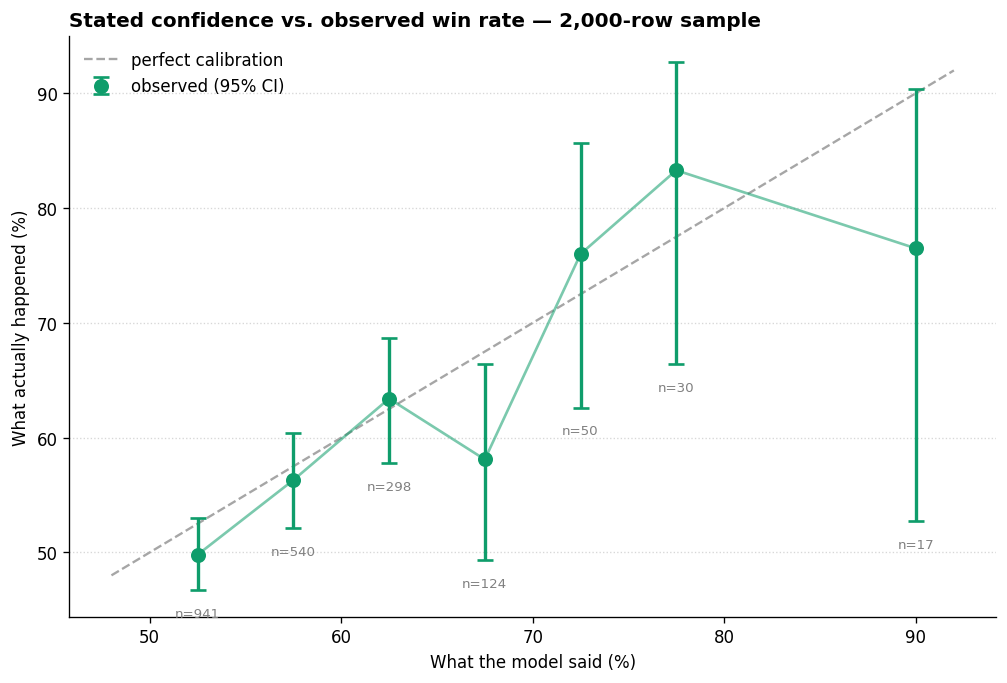

6 of 7 bands are statistically consistent with perfect calibration.


In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5.8), dpi=120)

ax.plot([48, 92], [48, 92], "--", color="gray", lw=1.4, alpha=.7,
        label="perfect calibration", zorder=1)

ax.errorbar(cal.said, cal.observed,
            yerr=[cal.observed - cal.ci_low, cal.ci_high - cal.observed],
            fmt="o", color="#0f9d6b", ms=8, lw=2, capsize=5, capthick=1.6,
            label="observed (95% CI)", zorder=3)
ax.plot(cal.said, cal.observed, "-", color="#0f9d6b", lw=1.6, alpha=.55, zorder=2)

for _, r in cal.iterrows():
    ax.annotate(f"n={r.n}", (r.said, r.ci_low), textcoords="offset points",
                xytext=(0, -16), ha="center", fontsize=8, color="gray")

ax.set_xlabel("What the model said (%)")
ax.set_ylabel("What actually happened (%)")
ax.set_title("Stated confidence vs. observed win rate — 2,000-row sample",
             fontweight="bold", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", ls=":", alpha=.5)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
plt.tight_layout()
plt.show()

n_ok = int(cal.consistent.sum())
print(f"{n_ok} of {len(cal)} bands are statistically consistent with perfect calibration.")


## 5. Why the error bars are the point

Look at how wide the intervals get above 70%. This sample simply does not contain enough high-confidence matches to pin those rates down, and any curve drawn without error bars would be inviting you to over-read noise.

Measured on the **full 51,397-match file** (49,353 matches once cold-start rows are dropped), the bands are tight and every one lands within three points of its stated confidence:

| Model said | Matches | Actually won | Gap |
|---|---|---|---|
| 50–55% | 22,536 | 51.7% | −0.8 |
| 55–60% | 14,301 | 54.7% | −2.8 |
| 60–65% | 7,080 | 59.6% | −2.9 |
| 65–70% | 3,006 | 66.4% | −1.1 |
| 70–75% | 1,338 | 71.5% | −1.0 |
| 75–80% | 630 | 78.4% | +0.9 |
| 80%+ | 462 | 82.0% | — |

That is what 25× more data buys you: the same curve, without the guesswork.

## 6. The cold-start caveat

Every player enters at 1500. Until a rating has moved, the model has nothing to say and outputs exactly 0.500. Those rows are not wrong, just uninformative, and leaving them in drags aggregates toward the middle.

This sample already excludes them. In the full dataset they are 623 matches — 1.2% — and you filter them like this:


In [7]:
warm = m[(m.elo_a_pre != 1500) & (m.elo_b_pre != 1500)]
print(f"{len(m) - len(warm)} cold-start rows in this sample ({len(warm)} remain)")


0 cold-start rows in this sample (2000 remain)


## 7. Where to go next

- Treat `p_model` as a baseline and try to beat it with your own features.
- Or ignore `p_model` entirely and use `elo_a_pre`, `elo_b_pre`, `sol_a_pre`, `sol_b_pre` as leak-free inputs to your own classifier.
- Join on `player_id` to bring in `players.csv` and `ratings_history.csv` (full dataset) for form and trajectory features.

One caution worth repeating: the edge over a well-tuned match-level baseline is roughly **+0.005 Brier**. Real, reproducible, and modest. This dataset is an input to a model, not an edge in a box.
